# Module 2 — Titanic Exploratory Data Analysis (EDA) Pipeline

## 1. Missing-Value Handling Strategy & Justifications
* **deck (77.22% missing):** This exceeds the 30% reliability threshold rule. We explicitly choose to drop this column because imputing such a massive block of missing data would introduce heavy artificial bias.
* **age (19.87% missing):** This falls perfectly within the 5%–30% threshold rule. We retain this feature and will handle it via median imputation inside our machine learning training pipeline to avoid data leakage.
* **embarked / embark_town (0.22% missing):** These fall well below the 5% threshold rule. We drop these specific rows directly as it safely cleans the dataset without losing significant row volume.

## 2. Fare Distribution & Skewness Analysis
The central tendency metrics for `fare` follow a strict ordering of **Mean (32.20) > Median (14.45) > Mode (8.05)**. Because the mathematical mean sits significantly higher than the median and mode, the fare distribution is heavily **right-skewed**. A small group of wealthy first-class passengers paid exceptionally high ticket prices, creating a long right-side tail on the distribution plot.

## 3. Interpretation of Top Two Strongest Correlations
* **Fare & Pclass (-0.548 absolute correlation):** This is the strongest correlation on the chart. The negative sign represents an inverse relationship—as passenger class numbers decrease (moving from 3rd class up to 1st class), the ticket fare increases significantly.
* **SibSp & Parch (+0.414 absolute correlation):** This is the second strongest correlation. The positive sign reveals a strong family grouping behavior, confirming that passengers traveling with siblings or spouses were highly likely to also travel with parents or children.

## 4. Multivariate Data Story Interpretations
* **Chart 1 (Bar Plot):** Highlights the "women and children first" historical rescue rules. Females in 1st and 2nd class achieved a near-90% survival probability, whereas males across all classes faced the lowest survival outcomes.
* **Chart 2 (Box Plot):** Demonstrates that survival scales positively with fare pricing. Higher-paying passengers secured cabins located closer to the primary lifeboat launch decks.
* **Chart 3 (Violin Plot):** Shows a sharp survival expansion among early age buckets (ages 0-5), verifying that children were given priority during the ship's evacuation procedures.
* **Chart 4 (Point Plot):** Captures distinct survival differences based on where passengers boarded, showing that Cherbourg ('C') passengers experienced higher survival slopes across classes.


=== TASK 1: RETRIEVING DATA AND PROFILING METRICS ===

--- df.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB

Raw DataFrame Shape:

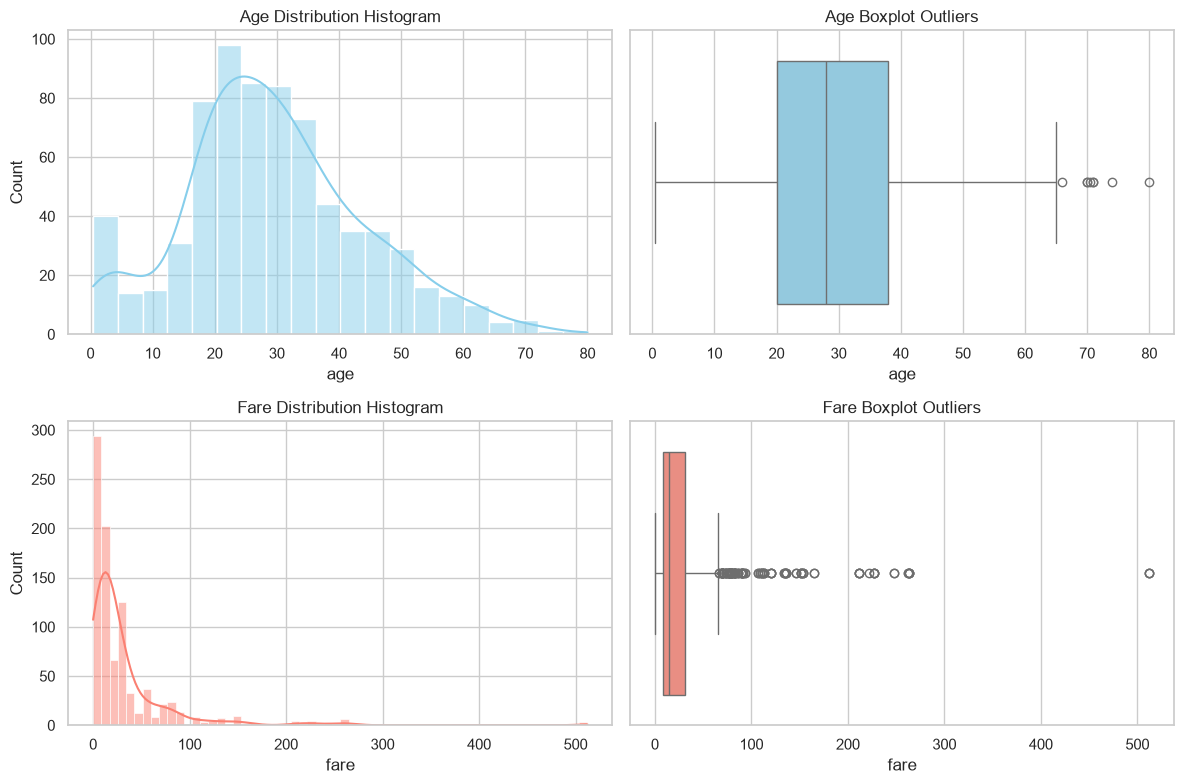


=== TASK 4: BIVARIATE BREAKDOWNS & CORRELATIONS ===
Survival Rate by Sex:
sex
female    0.740385
male      0.188908
Name: survived, dtype: float64

Survival Rate by Passenger Class (Pclass):
pclass
1    0.626168
2    0.472826
3    0.242363
Name: survived, dtype: float64

Survival Rate by Sex + Pclass combined:
sex     pclass
female  1         0.967391
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: survived, dtype: float64


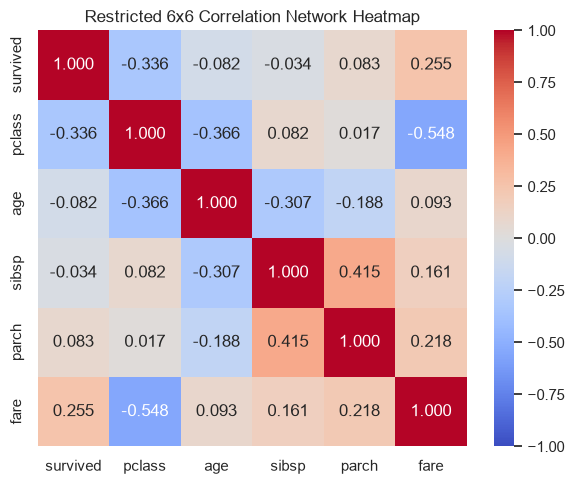


=== TASK 5: GENERATING MULTIVARIATE DATA STORY CHARTS ===


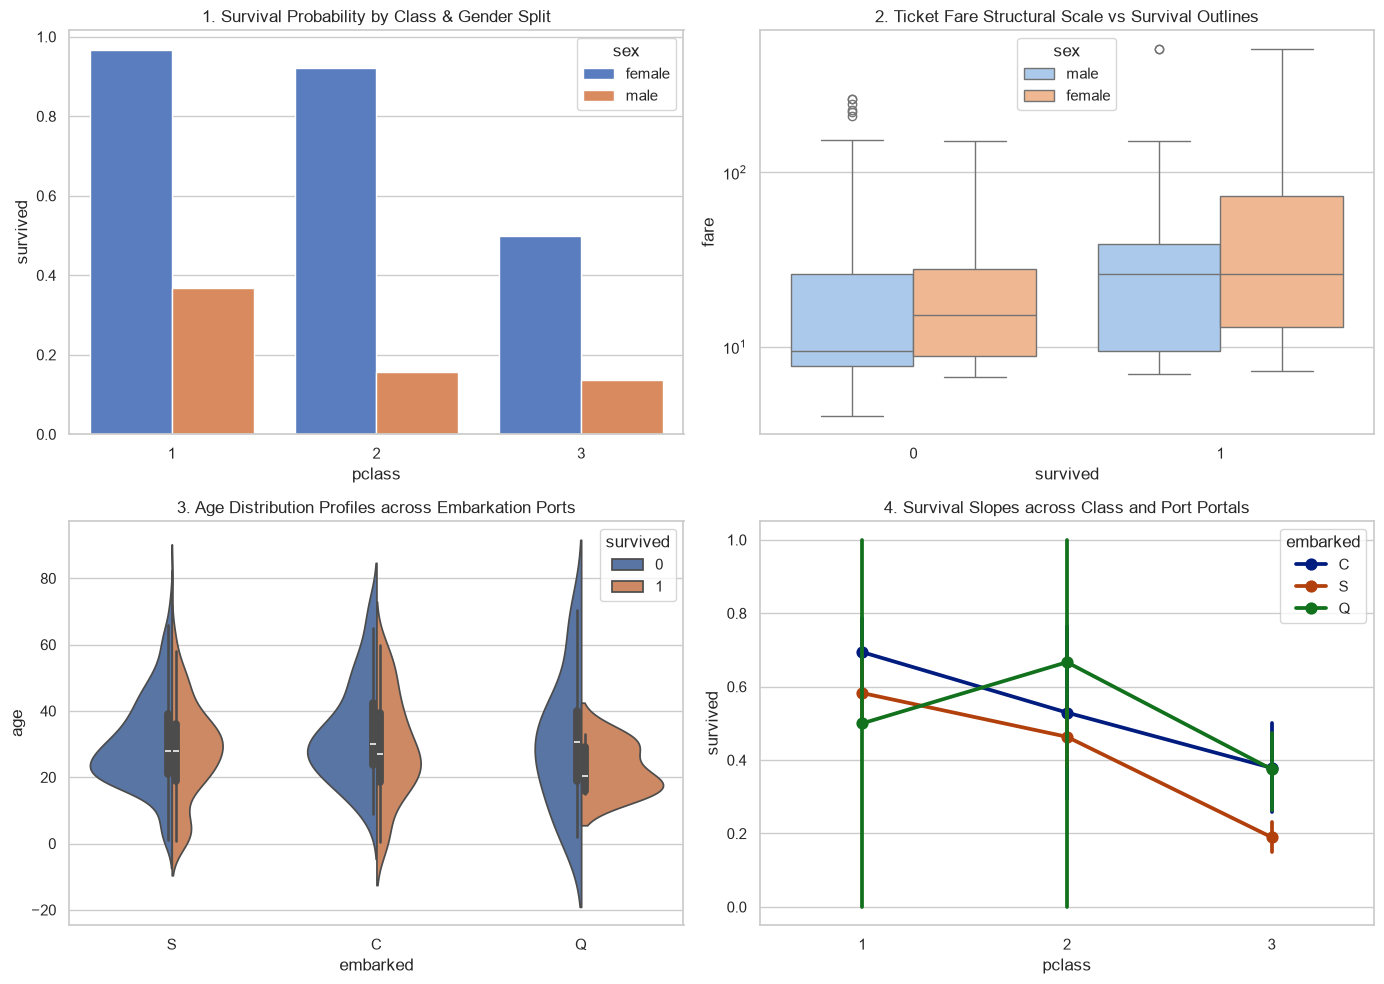


=== TASK 6: EXPLORATORY Z-SCORE SANITY CHECK ===
• Pre-scale  AGE -> Mean: 29.6421 | Std: 14.4929
  Post-scale AGE -> Mean: 0.0000 | Std: 1.0000
• Pre-scale  FARE -> Mean: 32.0967 | Std: 49.6975
  Post-scale FARE -> Mean: 0.0000 | Std: 1.0000


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Force matching production layout styles
sns.set_theme(style="whitegrid")
print("=== TASK 1: RETRIEVING DATA AND PROFILING METRICS ===")

# Ingest raw dataset exactly once
df_raw = sns.load_dataset('titanic')

# Profile raw layout structures
print("\n--- df.info() ---")
df_raw.info()
print(f"\nRaw DataFrame Shape: {df_raw.shape}")

# Calculate percentage of missing values per column
missing_pct = (df_raw.isnull().sum() / len(df_raw)) * 100
print("\n--- Missing Value Percentages per Affected Column ---")
print(missing_pct[missing_pct > 0])

# Commit localized offline fallback artifact immediately after loading
df_raw.to_csv("titanic.csv", index=False)
print("\n✅ Static fallback cache file successfully created as 'titanic.csv'.")


print("\n=== TASK 2 & 3: CLEANING & OUTLIER ASSESSMENTS ===")
# Apply missing threshold rules
df_cleaned = df_raw.drop(columns=['deck'])  # Drop column (>30% missing)
df_cleaned = df_cleaned.dropna(subset=['embarked', 'embark_town'])  # Drop rows (<5% missing)
print(f"Cleaned DataFrame Shape: {df_cleaned.shape}")

# Calculate IQR-based outlier counts for Age and Fare
for col in ['age', 'fare']:
    q1 = df_cleaned[col].quantile(0.25)
    q3 = df_cleaned[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df_cleaned[(df_cleaned[col] < lower_bound) | (df_cleaned[col] > upper_bound)]
    print(f"• {col.capitalize()} Outlier Count (IQR Rule): {len(outliers)} within bounds [{lower_bound:.2f}, {upper_bound:.2f}]")

# Compute Central Tendency Metrics for Fare skewness analysis
f_mean, f_median, f_mode = df_cleaned['fare'].mean(), df_cleaned['fare'].median(), df_cleaned['fare'].mode()[0]
print(f"Fare Skewness Reference Summary -> Mean: {f_mean:.2f} | Median: {f_median:.2f} | Mode: {f_mode:.2f}")

# Render Univariate Metric Plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df_cleaned['age'], kde=True, ax=axes[0, 0], color='skyblue').set_title('Age Distribution Histogram')
sns.boxplot(x=df_cleaned['age'], ax=axes[0, 1], color='skyblue').set_title('Age Boxplot Outliers')
sns.histplot(df_cleaned['fare'], kde=True, ax=axes[1, 0], color='salmon').set_title('Fare Distribution Histogram')
sns.boxplot(x=df_cleaned['fare'], ax=axes[1, 1], color='salmon').set_title('Fare Boxplot Outliers')
plt.tight_layout()
plt.show()


print("\n=== TASK 4: BIVARIATE BREAKDOWNS & CORRELATIONS ===")
print("Survival Rate by Sex:")
print(df_cleaned.groupby('sex', observed=False)['survived'].mean())
print("\nSurvival Rate by Passenger Class (Pclass):")
print(df_cleaned.groupby('pclass', observed=False)['survived'].mean())
print("\nSurvival Rate by Sex + Pclass combined:")
print(df_cleaned.groupby(['sex', 'pclass'], observed=False)['survived'].mean())

# Isolate exactly the six required columns for the correlation heatmap
numeric_cols = ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
corr_matrix = df_cleaned[numeric_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".3f", vmin=-1, vmax=1)
plt.title('Restricted 6x6 Correlation Network Heatmap')
plt.tight_layout()
plt.show()


print("\n=== TASK 5: GENERATING MULTIVARIATE DATA STORY CHARTS ===")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.barplot(data=df_cleaned, x='pclass', y='survived', hue='sex', ax=axes[0, 0], palette='muted', errorbar=None)
axes[0, 0].set_title('1. Survival Probability by Class & Gender Split')
sns.boxplot(data=df_cleaned, x='survived', y='fare', hue='sex', ax=axes[0, 1], palette='pastel', log_scale=True)
axes[0, 1].set_title('2. Ticket Fare Structural Scale vs Survival Outlines')
sns.violinplot(data=df_cleaned, x='embarked', y='age', hue='survived', split=True, ax=axes[1, 0], palette='deep')
axes[1, 0].set_title('3. Age Distribution Profiles across Embarkation Ports')
sns.pointplot(data=df_cleaned, x='pclass', y='survived', hue='embarked', ax=axes[1, 1], palette='dark')
axes[1, 1].set_title('4. Survival Slopes across Class and Port Portals')
plt.tight_layout()
plt.show()


print("\n=== TASK 6: EXPLORATORY Z-SCORE SANITY CHECK ===")
for col in ['age', 'fare']:
    mean_val = df_cleaned[col].mean()
    std_val = df_cleaned[col].std()
    z_scores = (df_cleaned[col] - mean_val) / std_val
    print(f"• Pre-scale  {col.upper()} -> Mean: {mean_val:.4f} | Std: {std_val:.4f}")
    print(f"  Post-scale {col.upper()} -> Mean: {z_scores.mean():.4f} | Std: {z_scores.std():.4f}")
